In [1]:
using Revise

using MarineHydro
using PyCall
using StaticArrays

# try using meshes
#using CairoMakie
using Meshes


[0.0, 0.0, -0.1]
[0.0, 0.0, -0.2]


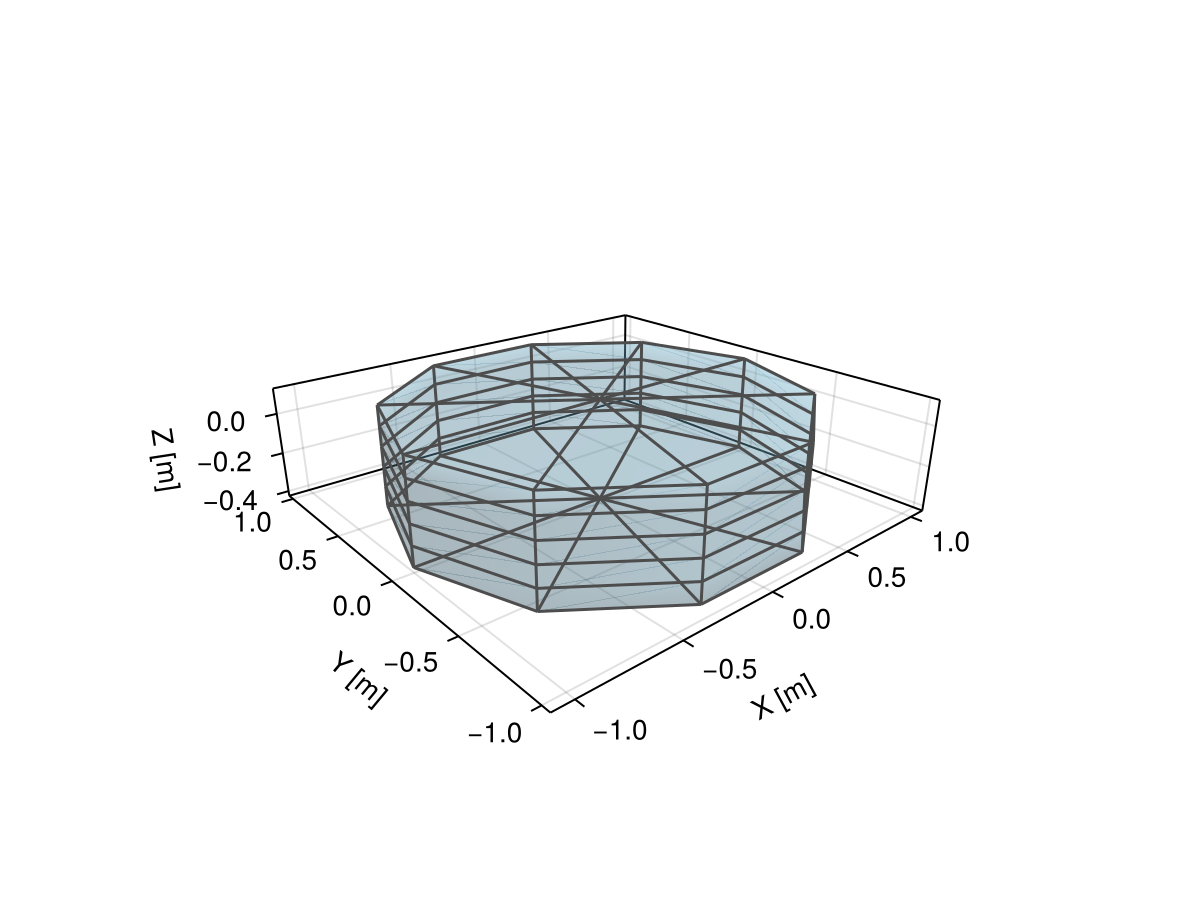

In [2]:
cyl = CylinderSurface(
    Meshes.Point(0.0, 0.0, -0.4),  # bottom center
    Meshes.Point(0.0, 0.0, 0.1),  # top center
    1.0                   # radius
)

cyl_mesh = Meshes.discretize(cyl, RegularDiscretization(10,5))

cyl_body = FloatingBody(cyl_mesh, ["Surge","Sway","Heave","Roll","Pitch","Yaw"], "cyl"; rotation_center=[0.0,0.0,-0.1], center_of_mass=[0.0,0.0,-0.2], mass=1000)

println(cyl_body.rotation_center)
println(cyl_body.center_of_mass)

cyl_mesh_immersed = get_immersed_mesh(cyl_mesh)

cyl_body_heave = FloatingBody(cyl_mesh_immersed, ["Surge","Heave","Pitch"], "cyl"; rotation_center=[0.0,0.0,-0.1], center_of_mass=[0.0,0.0,-0.2], mass=1000)

custom_cyl_mesh = MarineHydro.Mesh(cyl_mesh_immersed)

custom_cyl_body_heave = FloatingBody(
    custom_cyl_mesh,
    ["Surge","Heave","Pitch"],
    "cyl_custom";
    rotation_center = [0.0, 0.0, -0.1],
    center_of_mass = [0.0, 0.0, -0.2],
    mass = 1000
)

viz(cyl_body.mesh; color=:skyblue, alpha = 0.25, showsegments=true)

In [3]:
function compare_array_field(name::Symbol, A, B; atol=1e-8, rtol=1e-6, verbose=true)
    size(A) == size(B) || error("Size mismatch for $name: $(size(A)) vs $(size(B))")

    if isempty(A) && isempty(B)
        println(rpad(String(name), 25), " empty field, skipped ⚪")
        return (
            name=name,
            ok=true,
            skipped=true,
            maxdiff=NaN,
            reldiff=NaN,
            worst_index=nothing,
            orig_value=nothing,
            meshes_value=nothing,
            diff=nothing,
        )
    end

    Δ = A .- B
    absΔ = abs.(Δ)

    maxdiff = maximum(absΔ)
    idx = argmax(absΔ)

    scale = max(maximum(abs.(A)), maximum(abs.(B)), eps(Float64))
    reldiff = maxdiff / scale

    ok = maxdiff <= atol + rtol * scale

    println(
        rpad(String(name), 25),
        " max abs diff = ", maxdiff,
        " | rel diff = ", reldiff,
        ok ? " ✅" : " ❌"
    )

    if verbose && !ok
        println("  worst index = ", idx)
        println("  orig        = ", A[idx])
        println("  meshes      = ", B[idx])
        println("  diff        = ", Δ[idx])
    end

    return (
        name=name,
        ok=ok,
        skipped=false,
        maxdiff=maxdiff,
        reldiff=reldiff,
        worst_index=idx,
        orig_value=A[idx],
        meshes_value=B[idx],
        diff=Δ[idx],
    )
end

function compare_hydro_coefficients(orig, meshes; atol=1e-8, rtol=1e-6, verbose=true)
    fields = intersect(propertynames(orig), propertynames(meshes))

    results = Dict{Symbol, Any}()

    for name in fields
        A = getproperty(orig, name)
        B = getproperty(meshes, name)

        results[name] = compare_array_field(
            name,
            A,
            B;
            atol=atol,
            rtol=rtol,
            verbose=verbose
        )
    end

    return results
end

compare_hydro_coefficients (generic function with 1 method)

In [4]:
# solve for hydrodynamic coefficients and compare between meshes and custom mesh

ωs = range(0.1, 1.0, length=10)
β0 = 0.0
params_all = (wave_frequencies=ωs, radiating_dofs=[:Surge,:Heave,:Pitch], wave_directions=[β0])

# test all the formulations
formulations = (
    "direct Wu"          => DirectBEM(),
    "indirect Wu"        => IndirectBEM(),
    "direct Delhommeau"  => DirectBEM("ExactGuevelDelhommeau"),
    "indirect Delhommeau"=> IndirectBEM("ExactGuevelDelhommeau"),
)

for (name, form) in formulations
    data_orig = hydrodynamic_coefficients(custom_cyl_body_heave, params_all, form)
    data_meshes = hydrodynamic_coefficients(cyl_body_heave, params_all, form)

    println("Comparing $name formulation:")
    comparison = compare_hydro_coefficients(
        data_orig,
        data_meshes;
        atol=1e-8,
        rtol=1e-6
    )
end


Comparing direct Wu formulation:
added_mass                max abs diff = 4.547473508864641e-13 | rel diff = 1.853154499374412e-16 ✅
radiation_damping         max abs diff = 5.684341886080802e-14 | rel diff = 1.6817127586172355e-16 ✅
diffraction_force         max abs diff = 2.2737367544323206e-13 | rel diff = 9.493552077642455e-17 ✅
Froude_Krylov_force       max abs diff = 0.0 | rel diff = 0.0 ✅
excitation_force          max abs diff = 2.331362613788934e-13 | rel diff = 8.096322628006479e-18 ✅
Comparing indirect Wu formulation:
added_mass                max abs diff = 4.547473508864641e-13 | rel diff = 2.0937365695202787e-16 ✅
radiation_damping         max abs diff = 1.1368683772161603e-13 | rel diff = 3.905939073804912e-16 ✅
diffraction_force         max abs diff = 2.278173318171838e-13 | rel diff = 1.0639302244157595e-16 ✅
Froude_Krylov_force       max abs diff = 0.0 | rel diff = 0.0 ✅
excitation_force          max abs diff = 2.275141446545404e-13 | rel diff = 7.900331686238125e-18 ✅

In [5]:
# multibody hydrodynamics comparison
cyl2 = CylinderSurface(
    Meshes.Point(1.0, 0.0, -0.4),  # bottom center
    Meshes.Point(1.0, 0.0, 0.1),  # top center
    0.2                   # radius
)
cyl_mesh2 = Meshes.discretize(cyl2, RegularDiscretization(10,5))
cyl_mesh_immersed2 = get_immersed_mesh(cyl_mesh2)
cyl_body_heave2 = FloatingBody(cyl_mesh_immersed2, ["Surge","Heave","Pitch"], "cyl"; rotation_center=[0.0,0.0,-0.1], center_of_mass=[0.0,0.0,-0.2], mass=1000)
custom_cyl_mesh2 = MarineHydro.Mesh(cyl_mesh_immersed2)
custom_cyl_body_heave2 = FloatingBody(
    custom_cyl_mesh2,
    ["Surge","Heave","Pitch"],
    "cyl_custom";
    rotation_center = [0.0, 0.0, -0.1],
    center_of_mass = [0.0, 0.0, -0.2],
    mass = 1000
)

combined_cyls = combine_fb_meshes([cyl_body_heave, cyl_body_heave2])
combined_custom_cyls = custom_cyl_body_heave + custom_cyl_body_heave2

println(combined_custom_cyls)

ωs = range(0.1, 1.0, length=3)
β0 = 0.0
params_all = (wave_frequencies=ωs, wave_directions=[β0], radiating_dofs=[:cyl__Heave,:cyl_2__Heave,:cyl__Pitch,:cyl_2__Pitch])
params_all_custom = (wave_frequencies=ωs, wave_directions=[β0], radiating_dofs=[:cyl_custom__Heave,:cyl_custom_2__Heave,:cyl_custom__Pitch,:cyl_custom_2__Pitch])

# test all the formulations
formulations = (
    "direct Wu"          => DirectBEM(),
    "indirect Wu"        => IndirectBEM(),
    "direct Delhommeau"  => DirectBEM("ExactGuevelDelhommeau"),
    "indirect Delhommeau"=> IndirectBEM("ExactGuevelDelhommeau"),
)

for (name, form) in formulations
    data_orig = hydrodynamic_coefficients(combined_custom_cyls, params_all_custom, form)
    data_meshes = hydrodynamic_coefficients(combined_cyls, params_all, form)

    println("Comparing $name formulation:")
    comparison = compare_hydro_coefficients(
        data_orig,
        data_meshes;
        atol=1e-8,
        rtol=1e-6
    )

end


FloatingBody{MarineHydro.Mesh{Float64, Matrix{Float64}, Matrix{Int64}, Matrix{Number}, Matrix{Number}, Vector{Float64}, Vector{Number}}, Nothing, @NamedTuple{cyl_custom__Surge::Matrix{Float64}, cyl_custom__Heave::Matrix{Float64}, cyl_custom__Pitch::Matrix{Float64}, cyl_custom_2__Surge::Matrix{Float64}, cyl_custom_2__Heave::Matrix{Float64}, cyl_custom_2__Pitch::Matrix{Float64}}, Nothing, Vector{Float64}, Nothing}(MarineHydro.Mesh{Float64, Matrix{Float64}, Matrix{Int64}, Matrix{Number}, Matrix{Number}, Vector{Float64}, Vector{Number}}([1.0 0.0 -0.4; 0.8090169943749475 0.5877852522924731 -0.4; 0.8090169943749476 0.5877852522924731 -0.30000000000000004; 1.0 0.0 -0.4; 0.8090169943749476 0.5877852522924731 -0.30000000000000004; 1.0 0.0 -0.30000000000000004; 0.8090169943749475 0.5877852522924731 -0.4; 0.30901699437494745 0.9510565162951535 -0.4; 0.30901699437494745 0.9510565162951535 -0.30000000000000004; 0.8090169943749475 0.5877852522924731 -0.4; 0.30901699437494745 0.9510565162951535 -0.30

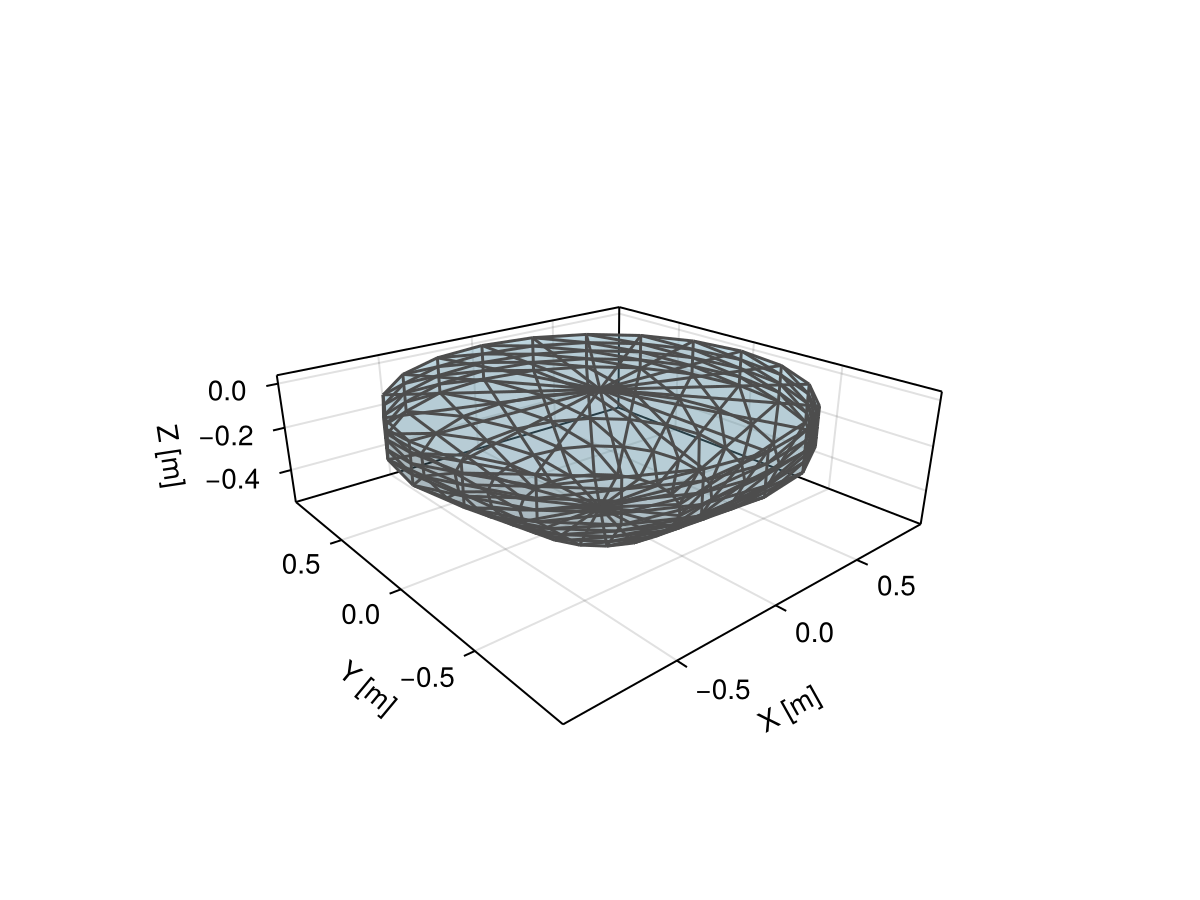

In [18]:
"""
    wavebot_mesh(; r1=0.88, r2=0.35, h1=0.17, h2=0.37,
                   scale_factor=1.0, freeboard=0.01,
                   ntheta=64, nz_cyl=4, nz_frustum=8,
                   caps=true)

Create a triangular surface mesh for the Sandia WaveBot hull.

Coordinates follow the Python version:

- waterline at `z = 0`
- top of cylinder at `z = freeboard`
- cylinder/frustum joint at `z = freeboard - h1`
- bottom of frustum at `z = freeboard - h1 - h2`
"""
function wavebot_mesh(;
    r1::Real = 0.88,
    r2::Real = 0.35,
    h1::Real = 0.17,
    h2::Real = 0.37,
    scale_factor::Real = 1.0,
    freeboard::Real = 0.01,
    ntheta::Int = 64,
    nz_cyl::Int = 4,
    nz_frustum::Int = 8,
    caps::Bool = true
)
    # scale dimensions
    r1 = Float64(r1 * scale_factor)
    r2 = Float64(r2 * scale_factor)
    h1 = Float64(h1 * scale_factor)
    h2 = Float64(h2 * scale_factor)
    freeboard = Float64(freeboard * scale_factor)

    # z locations
    ztop  = freeboard
    zjoin = freeboard - h1
    zbot  = freeboard - h1 - h2

    # build rings from bottom to top so side face orientation is outward
    z_frustum = collect(range(zbot, zjoin, length = nz_frustum + 1))
    z_cyl = collect(range(zjoin, ztop, length = nz_cyl + 1))[2:end]

    zs = [z_frustum; z_cyl]

    function radius_at_z(z)
        if z <= zjoin
            s = (z - zbot) / (zjoin - zbot)
            return (1 - s) * r2 + s * r1
        else
            return r1
        end
    end

    points = Tuple{Float64,Float64,Float64}[]

    # ring points
    for z in zs
        r = radius_at_z(z)
        for i in 0:ntheta-1
            θ = 2π * i / ntheta
            push!(points, (r * cos(θ), r * sin(θ), z))
        end
    end

    nrings = length(zs)

    idx(k, i) = (k - 1) * ntheta + mod1(i, ntheta)

    faces = Tuple{Int,Int,Int}[]

    # side panels
    for k in 1:nrings-1
        for i in 1:ntheta
            a = idx(k, i)
            b = idx(k, i + 1)
            c = idx(k + 1, i + 1)
            d = idx(k + 1, i)

            # two triangles per quad, outward-facing
            push!(faces, (a, b, c))
            push!(faces, (a, c, d))
        end
    end

    if caps
        # bottom cap, outward normal downward
        ibot_center = length(points) + 1
        push!(points, (0.0, 0.0, zbot))

        for i in 1:ntheta
            push!(faces, (ibot_center, idx(1, i + 1), idx(1, i)))
        end

        # top cap, outward normal upward
        itop_center = length(points) + 1
        push!(points, (0.0, 0.0, ztop))

        for i in 1:ntheta
            push!(faces, (itop_center, idx(nrings, i), idx(nrings, i + 1)))
        end
    end

    connec = connect.(faces, Triangle)

    return SimpleMesh(points, connec)
end

mesh = wavebot_mesh(
    ntheta = 20,
    nz_cyl = 4,
    nz_frustum = 4,
    caps = true
)

viz(mesh; color=:skyblue, alpha = 0.25, showsegments=true)